# 8. Face models and an end-to-end effect

[All tutorials](https://github.com/bateni1380/landpy/tree/master/tutorials) · [Open in Colab](https://colab.research.google.com/github/bateni1380/landpy/blob/master/tutorials/8-face-models-and-effects.ipynb)

## Goal

Use the four original face-model APIs together: detect → crop → landmark or segment → filter → return the edit to the image. Downloads are cached, and inference preserves the supplied image and its checkpoints.

## Setup

Run every cell in order. Python 3.10+ is required; use Python 3.10–3.13 for TensorFlow examples. The first cell installs the pinned release if needed. A CPU is enough.

In [1]:
import importlib.metadata
import subprocess
import sys
try:
    installed = importlib.metadata.version('landpy')
except importlib.metadata.PackageNotFoundError:
    installed = None
if installed != '0.1.0':
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'landpy==0.1.0'])
import numpy as np
import matplotlib.pyplot as plt
from landpy import ImageLand, MarksLand, SquareMarks, QuadMarks, DualMarks, HeatLand, Filter, Debugger
plt.rcParams.update({'figure.figsize': (9, 4), 'axes.titlesize': 12})

The model examples need the optional TensorFlow dependencies. Model weights download only when a model is constructed. Reuse the cache on later runs.

In [2]:
import importlib.util
if importlib.util.find_spec('tensorflow') is None or importlib.util.find_spec('tf_keras') is None:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'landpy[tensorflow]==0.1.0'])
import warnings
warnings.filterwarnings("ignore", message=r"(?s).*tf.lite.Interpreter is deprecated.*", category=UserWarning)

## Steps

### 1. Load a reproducible example

The image below is the original repository test fixture. Its original photographer/license was not recorded. Use your own image when redistributing results. For your own image, replace this loading cell with `ImageLand("your-image.jpg")`.

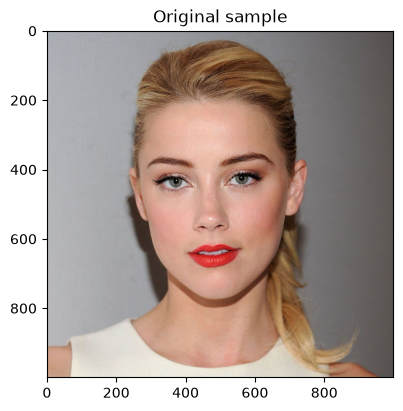

In [3]:
from pathlib import Path
import requests
local = Path('examples/assets/face.jpg')
if not local.exists():
    local = Path('../examples/assets/face.jpg')
if local.exists():
    photo = ImageLand(local)
else:
    from io import BytesIO
    from PIL import Image
    response = requests.get('https://raw.githubusercontent.com/bateni1380/landpy/master/examples/assets/face.jpg', timeout=30)
    response.raise_for_status()
    photo = ImageLand(Image.open(BytesIO(response.content)))
photo.show('Original sample')
original = photo.get_image().copy()

### 2. Detect a face and six keypoints

FaceTracker uses short-range BlazeFace. Scores are sigmoid probabilities and overlapping boxes are suppressed. `threshold` returns all qualifying detections; `top_k` limits them. `FacePoints` combines a bounding box, six keypoints, and probability `p`. The class name is historical: this method detects each image independently.

INFO: Created TensorFlow Lite XNNPACK delegate for CPU.


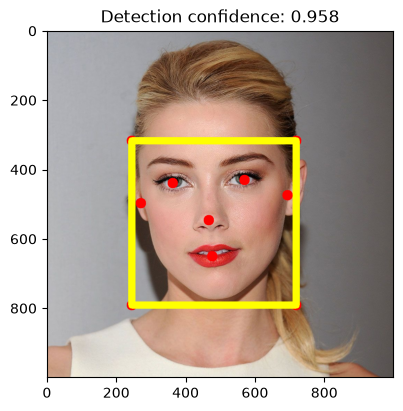

In [4]:
from landpy.pretrained_models import FaceTracker, FaceLandmarksDetector, FaceLandmarksIndices, FaceSegmentationDetector, ExpressionDetector
tracker = FaceTracker()
faces = tracker.detect_faces(photo, threshold=.5, top_k=1)
assert faces, 'No face detected; try a closer, front-facing portrait.'
face = faces[0]
(photo + face.face_box + face.face_points).show(f'Detection confidence: {face.p:.3f}')
region = face.face_box.copy().expand(1.25)
working = photo.copy().zoom(region, save_trace=True)

### 3. Locate a face mesh and color the lips

Landmarks are returned in the crop’s pixel coordinates. `LIPS`, `LEFT_EYE`, `RIGHT_EYE` and the other original index groups can select regions. The presence value is a probability; it is separate from the detector confidence.

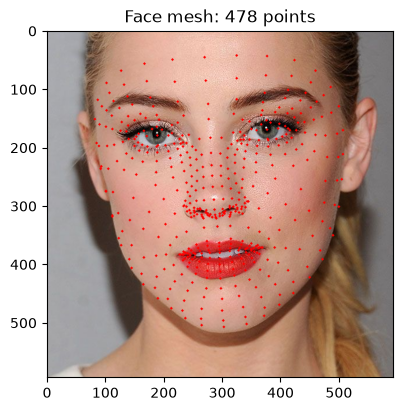

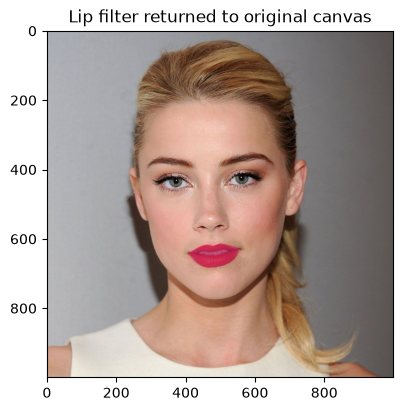

Mesh presence: 1.0


In [5]:
landmarks, presence = FaceLandmarksDetector().detect_face_landmarks(working)
preview = working.copy()
preview.ADDED_POINTS_RADIOUS = .3
(preview + landmarks).show(f'Face mesh: {len(landmarks.get_marks())} points')
lips = landmarks[FaceLandmarksIndices.LIPS].to_heat()
colored = working.copy(copy_trace=True).implant_filter(Filter('#c32660', .65), lips)
colored.retrace().show('Lip filter returned to original canvas')
print('Mesh presence:', round(presence, 4))

### 4. Segment and classify a cropped face

The segmentation map is resized to the input crop’s dimensions. ExpressionDetector returns scores in its `output_labels` order. These labels describe model classes, not a reliable measurement of feelings or intentions. All inference runs on copies.

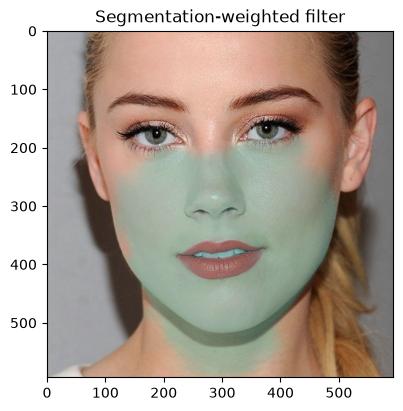

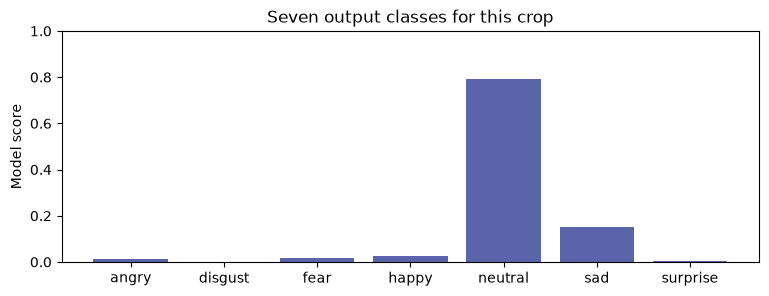

In [6]:
segmenter = FaceSegmentationDetector()
segmentation = segmenter.detect_face_segmentation(working)
working.copy().implant_filter(Filter('#35c8bb', .35), segmentation).show('Segmentation-weighted filter')
expression = ExpressionDetector()
scores = expression.detect_expression(working)[0]
fig, ax = plt.subplots(figsize=(9, 3))
ax.bar(expression.output_labels, scores, color='#5965a8')
ax.set(ylabel='Model score', ylim=(0, 1), title='Seven output classes for this crop')
plt.show()

## Checks

In [7]:
assert len(landmarks.get_marks()) in (468, 478)
assert landmarks.shape == working.shape
assert segmentation.shape == working.shape
assert 0 <= presence <= 1
assert scores.shape == (7,)
np.testing.assert_allclose(scores.sum(), 1, atol=1e-4)
np.testing.assert_array_equal(photo.get_image(), original)
assert colored.shape == photo.shape

## Next steps

Try your own face image, keeping the same crop → predict → mask → filter → retrace flow. See the API guide for offline model paths and coordinate conventions.